In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10
import numpy as np
import matplotlib.pyplot as plt


In [2]:
# Load CIFAR-10 dataset
(x_train, _), (x_test, _) = cifar10.load_data()  # Ignore labels for autoencoder

# Normalize the images
x_train = x_train / 255.0
x_test = x_test / 255.0


In [3]:
# Input shape
input_shape = (32, 32, 3)

# Encoder
encoder = models.Sequential([
    layers.Input(shape=input_shape),
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2), padding='same'),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2), padding='same'),
])

# Decoder
decoder = models.Sequential([
    layers.Conv2D(64, (3, 3), activation='relu', padding='same', input_shape=(8, 8, 64)),
    layers.UpSampling2D((2, 2)),
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.UpSampling2D((2, 2)),
    layers.Conv2D(3, (3, 3), activation='sigmoid', padding='same'),
])

# Combine encoder and decoder into an autoencoder model
autoencoder = models.Sequential([encoder, decoder])

# Compile the autoencoder
autoencoder.compile(optimizer='adam', loss='mse')
autoencoder.summary()


c:\Users\LENOVO\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 8, 8, 64)       │        19,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 32, 32, 3)      │        56,259 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 75,651 (295.51 KB)

 Trainable params: 75,651 (295.51 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
# Train the autoencoder
history = autoencoder.fit(
    x_train, x_train,
    epochs=10,
    batch_size=64,
    shuffle=True,
    validation_data=(x_test, x_test)
)


Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 67s 75ms/step - loss: 0.0148 - val_loss: 0.0045
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 57s 73ms/step - loss: 0.0044 - val_loss: 0.0038
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 57s 73ms/step - loss: 0.0037 - val_loss: 0.0036
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 61s 78ms/step - loss: 0.0033 - val_loss: 0.0030
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 71s 64ms/step - loss: 0.0030 - val_loss: 0.0027
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 114s 104ms/step - loss: 0.0027 - val_loss: 0.0025
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 66s 84ms/step - loss: 0.0025 - val_loss: 0.0024
Epoch 8/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 72s 91ms/step - loss: 0.0024 - val_loss: 0.0022
Epoch 9/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 58s 74ms/step - loss: 0.0023 - val_loss: 0.0021
Epoch 10/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 66s 85ms/step - loss: 0.0022 - val_loss: 0.0022


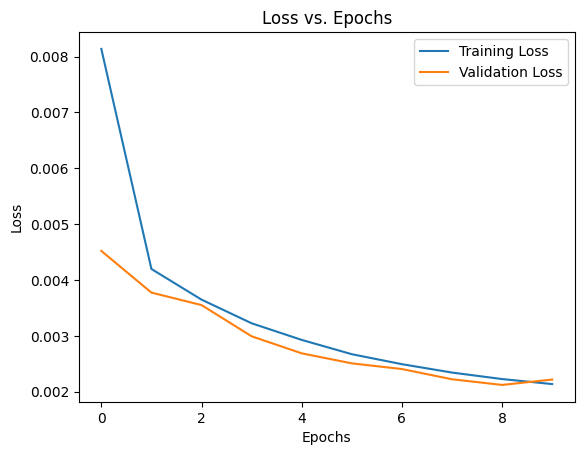

In [5]:
# Plot training and validation loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title("Loss vs. Epochs")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.show()


313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step


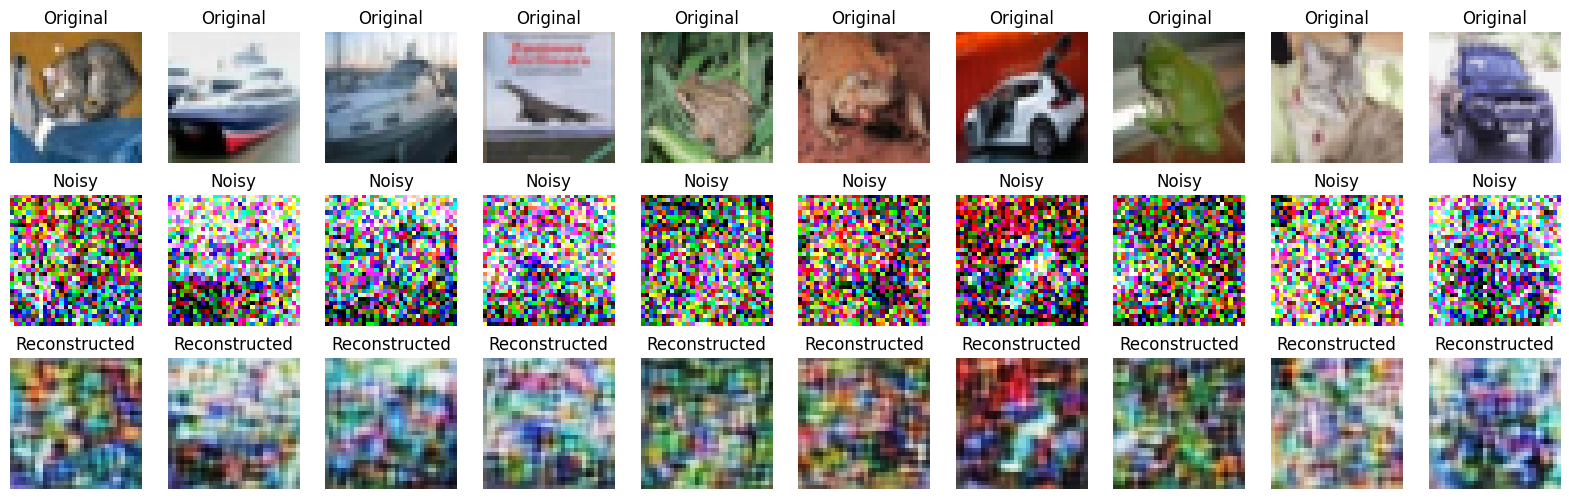

In [7]:
# Helper function to display original, noisy, and reconstructed images
def display_images(original, noisy, reconstructed, n=10):
    plt.figure(figsize=(20, 6))
    for i in range(n):
        # Original images
        plt.subplot(3, n, i + 1)
        plt.imshow(original[i])
        plt.title("Original")
        plt.axis('off')

        # Noisy images
        plt.subplot(3, n, i + n + 1)
        plt.imshow(noisy[i])
        plt.title("Noisy")
        plt.axis('off')

        # Reconstructed images
        plt.subplot(3, n, i + 2 * n + 1)
        plt.imshow(reconstructed[i])
        plt.title("Reconstructed")
        plt.axis('off')
    plt.show()

# Add noise to the test images
noise_factor = 0.5
x_test_noisy = x_test + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=x_test.shape)
x_test_noisy = np.clip(x_test_noisy, 0., 1.)

# Generate reconstructed images
reconstructed_images = autoencoder.predict(x_test_noisy)

# Display images
display_images(x_test, x_test_noisy, reconstructed_images, n=10)
